# New suitability model

Evaluates the model saved in `backend/models/`, trained with corrected labels.
This notebook only reads the model and never saves one. Charts go to `notebooks/figures_new_model/`.

Every score here is out-of-fold: each row is predicted by a model that never saw its alloy.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score
from sklearn.preprocessing import MultiLabelBinarizer

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "notebooks" / "figures_new_model"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

from backend.engine.preprocess import build_X, clean
from backend.engine.pricing import load_prices, price_category
from backend.engine.recommend import DATA_DIR, MODEL_DIR, recommend
from backend.engine.train import UNTOUCHED, fixed_labels, out_of_fold, scores

meta = json.loads((MODEL_DIR / "model_meta.json").read_text())
print("Model:", meta["model"], "| trained on", meta["trained_on"], "|", meta["n_train"], "rows")

Model: Gradient Boosting | trained on 2026-10-31 | 1401 rows


## 1. Training data

The original labels mostly came from one description per row, so a material usually had one class even when it qualifies for others. Rule-based label correction adds a class where the row's own data supports it. No label is removed and the original CSV is not changed.

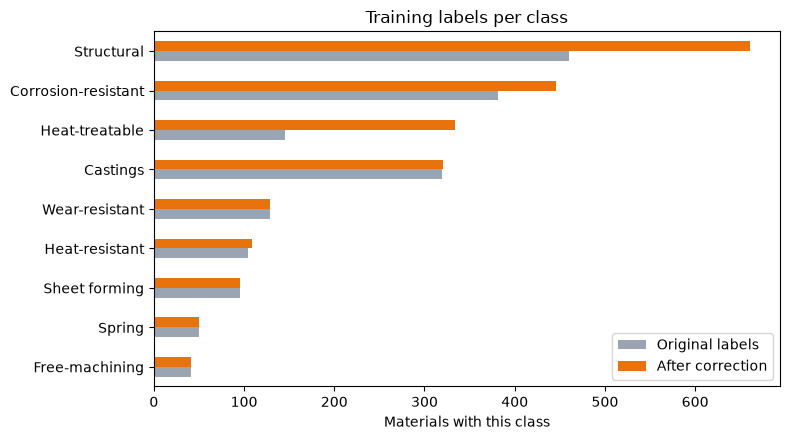

Labels added: {'Heat-treatable': 189, 'Structural': 201, 'Corrosion-resistant': 65, 'Heat-resistant': 5, 'Castings': 1} | total 461


In [2]:
df, _ = clean(pd.read_csv(DATA_DIR / "Data_labelled.csv"))
train = df[df["status"] == "train"].reset_index(drop=True)
train["price_category"] = train.apply(price_category, axis=1)
labels, added = fixed_labels(train, load_prices()["categories"])

mlb = MultiLabelBinarizer().fit(train["labels"])
classes = list(mlb.classes_)
Y_old, Y = mlb.transform(train["labels"]), mlb.transform(labels)
X = build_X(train, meta["features"])

counts = pd.DataFrame({"Original labels": Y_old.sum(0), "After correction": Y.sum(0)}, index=classes).sort_values("After correction")
ax = counts.plot.barh(figsize=(8, 4.5), color=["#9aa5b1", "#e8730c"])
ax.set_xlabel("Materials with this class")
ax.set_title("Training labels per class")
plt.tight_layout()
plt.savefig(FIG_DIR / "labels_per_class.png", dpi=150)
plt.show()
print("Labels added:", added, "| total", sum(added.values()))

## 2. Performance on unseen alloys

The fair test scores only classes that received no new labels, against the original labels. Scores on corrected classes partly reflect the correction rules, so read the two together.

In [3]:
P = out_of_fold(X, Y, train["group"])
pred = (P >= 0.5).astype(int)
fair = [classes.index(c) for c in UNTOUCHED]

ferrous = train["family"].eq("ferrous").values
overall = pd.DataFrame({"All": scores(Y, P), "Ferrous": scores(Y[ferrous], P[ferrous]), "Non-ferrous": scores(Y[~ferrous], P[~ferrous])}).T
display(overall)
print("Fair test, macro F1:", round(f1_score(Y_old[:, fair], pred[:, fair], average="macro", zero_division=0), 3))
print("Scores below 5% or above 95%:", f"{((P < .05) | (P > .95)).mean():.1%}")

,micro_F1,macro_F1,exact_match,hamming_loss
All,0.862,0.759,0.714,0.048
Ferrous,0.883,0.822,0.771,0.037
Non-ferrous,0.828,0.589,0.591,0.071


Fair test, macro F1: 0.657
Scores below 5% or above 95%: 92.9%


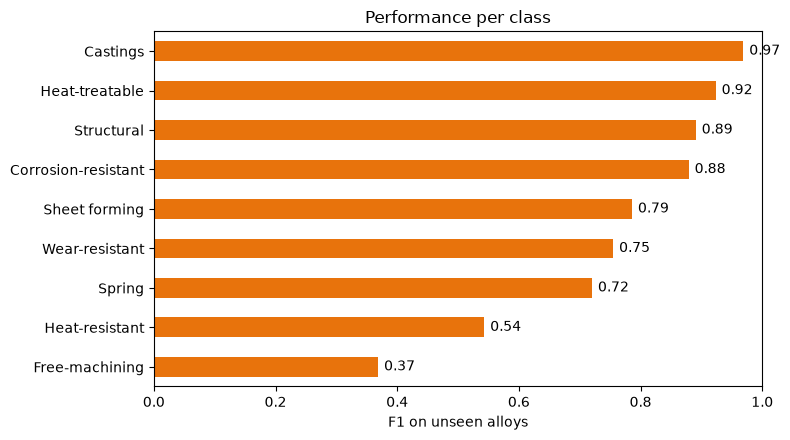

In [4]:
per_class = pd.Series({c: f1_score(Y[:, i], pred[:, i], zero_division=0) for i, c in enumerate(classes)}).sort_values()
ax = per_class.plot.barh(figsize=(8, 4.5), color="#e8730c")
ax.set_xlim(0, 1)
ax.set_xlabel("F1 on unseen alloys")
ax.set_title("Performance per class")
for i, v in enumerate(per_class):
    ax.text(v + .01, i, f"{v:.2f}", va="center")
plt.tight_layout()
plt.savefig(FIG_DIR / "f1_per_class.png", dpi=150)
plt.show()

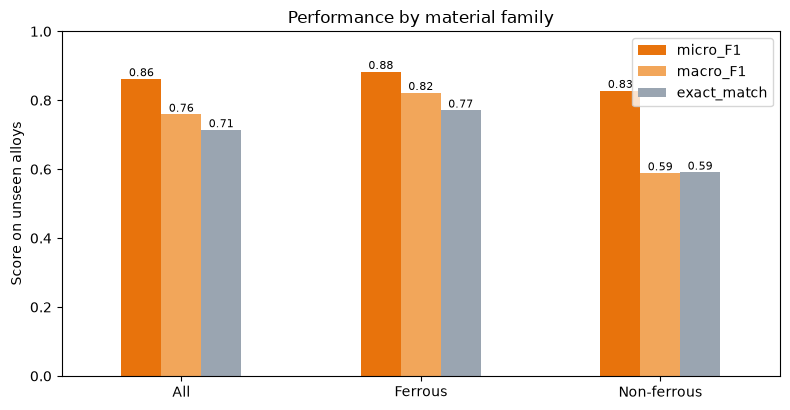

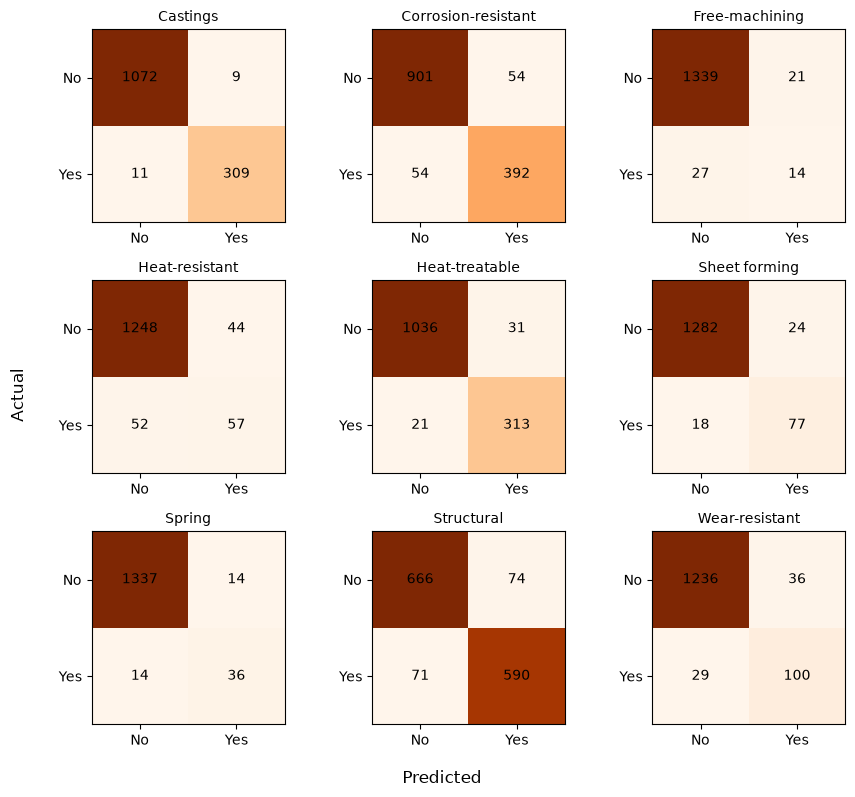

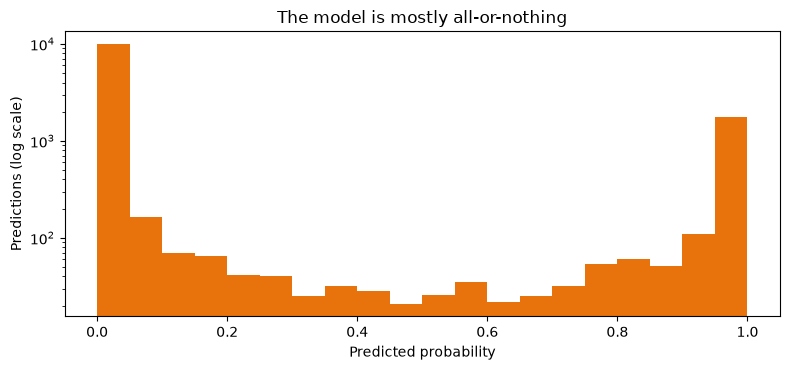

In [5]:
ax = overall[["micro_F1", "macro_F1", "exact_match"]].plot.bar(figsize=(8, 4.2), color=["#e8730c", "#f2a65a", "#9aa5b1"], rot=0)
ax.set_ylim(0, 1)
ax.set_ylabel("Score on unseen alloys")
ax.set_title("Performance by material family")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "f1_by_family.png", dpi=150)
plt.show()

from sklearn.metrics import multilabel_confusion_matrix
fig, axes = plt.subplots(3, 3, figsize=(9, 8))
for ax, c, m in zip(axes.flat, classes, multilabel_confusion_matrix(Y, pred)):
    ax.imshow(m, cmap="Oranges")
    ax.set_title(c, fontsize=10)
    ax.set_xticks([0, 1], ["No", "Yes"])
    ax.set_yticks([0, 1], ["No", "Yes"])
    for (r, k), v in np.ndenumerate(m):
        ax.text(k, r, v, ha="center", va="center")
fig.supxlabel("Predicted")
fig.supylabel("Actual")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_per_class.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(P.ravel(), bins=20, color="#e8730c")
ax.set_yscale("log")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Predictions (log scale)")
ax.set_title("The model is mostly all-or-nothing")
plt.tight_layout()
plt.savefig(FIG_DIR / "probability_distribution.png", dpi=150)
plt.show()

## 3. Performance per material standard

How well the model works across the eight standards in the dataset. A standard with few rows gives a less stable score.

,rows,alloys,micro_F1,macro_F1,exact_match,hamming_loss
CSN,171.0,160.0,0.808,0.721,0.626,0.065
JIS,67.0,59.0,0.837,0.785,0.672,0.050
ANSI,472.0,280.0,0.843,0.707,0.638,0.062
BS,72.0,62.0,0.849,0.775,0.722,0.048
NF,91.0,78.0,0.864,0.752,0.758,0.044
DIN,114.0,108.0,0.865,0.834,0.746,0.044
ISO,91.0,83.0,0.894,0.751,0.813,0.033
GOST,323.0,173.0,0.925,0.569,0.827,0.024


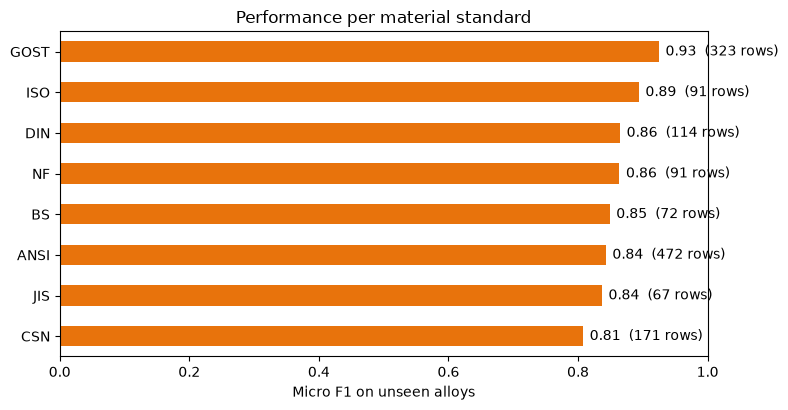

In [6]:
rows = {}
for std in sorted(train["Std"].dropna().unique()):
    m = train["Std"].eq(std).values
    rows[std] = {"rows": int(m.sum()), "alloys": int(train.loc[m, "group"].nunique()), **scores(Y[m], P[m])}
by_std = pd.DataFrame(rows).T.sort_values("micro_F1")
display(by_std)

ax = by_std["micro_F1"].astype(float).plot.barh(figsize=(8, 4.2), color="#e8730c")
ax.set_xlim(0, 1)
ax.set_xlabel("Micro F1 on unseen alloys")
ax.set_title("Performance per material standard")
for i, (v, n) in enumerate(zip(by_std["micro_F1"], by_std["rows"])):
    ax.text(float(v) + .01, i, f"{float(v):.2f}  ({int(n)} rows)", va="center")
plt.tight_layout()
plt.savefig(FIG_DIR / "f1_per_standard.png", dpi=150)
plt.show()

## 4. Results by part

Top five for seven searches, as the app shows them, then which standards reach the top 20. This runs the full engine: safety checks, suitability, usage ranking and TOPSIS.

Material Standard  \
Part            Rank                                           
Gear            1                          NF 16MC5       NF   
                2                         CSN 14230      CSN   
                3                          NF 16NC6       NF   
                4                    Steel SAE 1060     ANSI   
                5                    Steel SAE 1040     ANSI   
Shaft           1             Steel 20 GOST 1577-93     GOST   
                2                          DIN Ck35      DIN   
                3                            EN C25      ISO   
                4                         CSN 14148      CSN   
                5                         CSN 13220      CSN   
Connecting rod  1                    Steel SAE 1060     ANSI   
                2                    Steel SAE 1080     ANSI   
                3             Steel 50 GOST 1050-88     GOST   
                4                         NF 30CND8       NF   
                5          Steel 38ChA GOST 1577-93     GOST   
Spring          1                    Steel SAE 6150     ANSI   
                2                    Steel SAE 9260     ANSI   
                3                    Steel SAE 5160     ANSI   
                4                         CSN 12071      CSN   
                5                         CSN 13180      CSN   
Bracket         1                       DIN USt34-2      DIN   
                2                          NF A34-2       NF   
                3             Steel 10 GOST 1050-88     GOST   
                4             Aluminum Alloy 5154-O     ANSI   
                5     Aluminum Alloy Alclad 6061-T4     ANSI   
Pressure vessel 1           Steel ST3KP GOST 380-94     GOST   
                2             Steel 20 GOST 1577-93     GOST   
                3             Steel 20 GOST 1050-88     GOST   
                4         Steel 12MCh GOST 20072-74     GOST   
                5       Steel 12Ch1MF GOST 20072-74     GOST   
Tie rod         1                    Steel SAE 6150     ANSI   
                2                         EN 12Ni14      ISO   
                3                    Steel SAE 5150     ANSI   
                4                          NF E36-4       NF   
                5             Steel 30 GOST 1577-93     GOST   

                                  Group  Suitability %                 Usage  \
Part            Rank                                                           
Gear            1           alloy_steel           91.0  Common for this part   
                2           alloy_steel           90.8  Common for this part   
                3           alloy_steel           90.3  Common for this part   
                4          carbon_steel           87.2                         
                5          carbon_steel           85.1                         
Shaft           1          carbon_steel           89.4  Common for this part   
                2          carbon_steel           89.2  Common for this part   
                3          carbon_steel           88.7  Common for this part   
                4           alloy_steel           90.4  Common for this part   
                5           alloy_steel           89.9  Common for this part   
Connecting rod  1          carbon_steel           94.9                         
                2          carbon_steel           93.8                         
                3          carbon_steel           92.7                         
                4           alloy_steel           96.1  Common for this part   
                5           alloy_steel           95.8  Common for this part   
Spring          1           alloy_steel          100.0                         
                2           alloy_steel          100.0                         
                3           alloy_steel           99.9                         
                4          spring_steel          100.0  Common for this pa

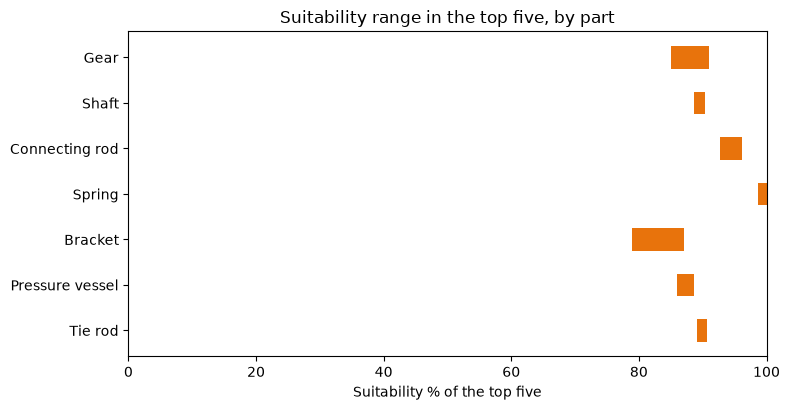

,Gear,Shaft,Connecting rod,Spring,Bracket,Pressure vessel,Tie rod
ANSI,4,3,6,15,12,8,12
BS,1,2,0,1,0,0,0
CSN,6,2,1,2,2,2,1
DIN,3,2,0,0,1,1,0
GOST,0,4,8,1,3,7,3
ISO,2,6,3,0,0,2,3
JIS,0,0,0,1,1,0,0
NF,4,1,2,0,1,0,1


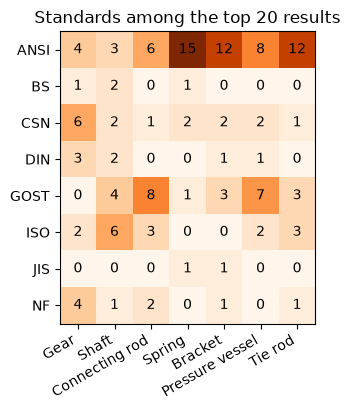

In [7]:
common = dict(environment="dry_indoor", cost_priority="important", weight_priority="not_important")
searches = {
    "Gear": dict(function="gear", design_inputs={"P_kW": 5, "N_rpm": 1440, "m_mm": 3, "z": 20, "b_mm": 30}, properties=["Wear-resistant", "Heat-treatable"], primary_property="Wear-resistant"),
    "Shaft": dict(function="shaft", design_inputs={"P_kW": 10, "N_rpm": 960, "M_Nm": 150, "d_mm": 30}, properties=["Heat-treatable", "Structural"], primary_property="Heat-treatable"),
    "Connecting rod": dict(function="general", part_type="rod", design_inputs={"section": "rectangle", "b_mm": 18, "h_mm": 30, "F_kN": 25, "M_Nm": 40, "Kt": 2, "L_mm": 150, "loading": "shock"}, properties=["Heat-treatable", "Structural"], primary_property="Heat-treatable"),
    "Spring": dict(function="spring", design_inputs={"F_N": 300, "Dm_mm": 40, "dw_mm": 6, "loading": "cyclic"}, properties=["Spring"]),
    "Bracket": dict(function="beam", design_inputs={"F_N": 500, "L_mm": 200, "b_mm": 20, "h_mm": 30}, properties=["Structural"]),
    "Pressure vessel": dict(function="pressure_vessel", design_inputs={"p_MPa": 2, "D_mm": 300, "t_mm": 5}, properties=["Structural"]),
    "Tie rod": dict(function="tie", design_inputs={"F_kN": 20, "d_mm": 16}, properties=["Structural"]),
}
top, standards = [], {}
for part, form in searches.items():
    res = recommend({**common, **form, "top_n": 5})  # the same list the app shows
    if not res["results"]:
        print(part, "-", res.get("message"))
    for x in res["results"]:
        top.append({"Part": part, "Rank": x["rank"], "Material": x["material"], "Standard": x["standard"], "Group": x["material_group"],
                    "Suitability %": x["suitability_pct"], "Usage": x["usage"], "Safety factor": x["min_fos"]})
    wider = recommend({**common, **form, "top_n": 20})["results"]
    standards[part] = pd.Series([x["standard"] for x in wider]).value_counts()
top = pd.DataFrame(top)
display(top.set_index(["Part", "Rank"]))

spread = top.groupby("Part", sort=False)["Suitability %"].agg(["min", "max"])
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(spread.index, spread["max"] - spread["min"], left=spread["min"], color="#e8730c", height=.5)
ax.set_xlim(0, 100)
ax.set_xlabel("Suitability % of the top five")
ax.set_title("Suitability range in the top five, by part")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG_DIR / "top5_suitability_by_part.png", dpi=150)
plt.show()

by_part = pd.DataFrame(standards).fillna(0).astype(int)
display(by_part)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
im = ax.imshow(by_part.values, cmap="Oranges")
ax.set_xticks(range(by_part.shape[1]), by_part.columns, rotation=30, ha="right")
ax.set_yticks(range(by_part.shape[0]), by_part.index)
for (r, c), v in np.ndenumerate(by_part.values):
    ax.text(c, r, v, ha="center", va="center")
ax.set_title("Standards among the top 20 results")
plt.tight_layout()
plt.savefig(FIG_DIR / "standards_in_results.png", dpi=150)
plt.show()

## 5. Limits

- Corrected labels come from engineering rules, so the model partly learns those rules.
- The model predicts application classes. It does not know the load on a specific part, so suitability is not part-specific by itself.
- Rare classes have few examples, and the dataset has no toughness, hot strength or measured composition.
- Results are first estimates. Complex parts still need FEA or testing.